# 02 · Escalado, PCA y Selección de Variables — Customer Churn

En este segundo cuaderno comparamos distintas alternativas de preparación de los datos para predecir el abandono de clientes (`abandono`), utilizando exclusivamente el conjunto de entrenamiento (`train.csv`).

Siguiendo el procedimiento de clase:
1. Usamos como modelo de referencia una **Regresión Logística** con pesos balanceados (`class_weight="balanced"`), igual que en el notebook de selección de características del curso.
2. Evaluamos cada opción mediante **validación cruzada estratificada de 10 particiones** (`StratifiedKFold(n_splits=10)`).
3. Todo el escalado, PCA o selector de variables se ajusta **dentro del pipeline**, evitando cualquier tipo de fuga de información (*data leakage*).
4. El conjunto de prueba (`test.csv`) permanece reservado para la evaluación final en el notebook 04.


## 1. Configuración de rutas

Definimos las rutas del proyecto y la variable `EN_COLAB` para permitir su ejecución local o en Google Colab.


In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install imbalanced-learn -q
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/churn/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_MODELOS = RUTA_BASE + "models/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
RUTA_FIGURAS = RUTA_BASE + "figuras/"


## 2. Importaciones

Importamos las librerías necesarias de scikit-learn e imbalanced-learn para escalado, reducción de dimensionalidad, selección de características, modelado y validación cruzada.


In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

for ruta in [RUTA_MODELOS, RUTA_RESULTADOS, RUTA_FIGURAS]:
    os.makedirs(ruta, exist_ok=True)


## 3. Cargar el conjunto de entrenamiento

Cargamos el archivo `train.csv` generado por el notebook 01. Separamos las variables predictoras `X_train` y la variable objetivo `y_train`.


In [3]:
train = pd.read_csv(RUTA_DATOS + "train.csv")

X_train = train.drop(columns="abandono")
y_train = train["abandono"]

print("Filas de entrenamiento:", len(train))
print("Variables predictoras (entradas):", X_train.shape[1])
print("\nDistribución de la variable objetivo:")
print(y_train.value_counts())
print(f"Proporción de abandono: {y_train.mean():.4f}")


Filas de entrenamiento: 2520
Variables predictoras (entradas): 11

Distribución de la variable objetivo:
abandono
0    2124
1     396
Name: count, dtype: int64
Proporción de abandono: 0.1571


Trabajamos con 2.520 registros de entrenamiento, 11 variables de entrada y 396 clientes que abandonaron (15,71 %).


## 4. Configuración de validación cruzada y métricas

Configuramos una validación cruzada estratificada de 10 particiones (`StratifiedKFold(n_splits=10, shuffle=True, random_state=42)`).
Definimos el $F_1	ext{-score}$ de la clase positiva (`abandono`) como métrica principal, acompañada de precisión y recall.


In [4]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
particiones_cv = list(cv.split(X_train, y_train))

metricas = {
    "f1": make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0)
}

print(f"Validación cruzada lista con {len(particiones_cv)} particiones estratificadas.")


Validación cruzada lista con 10 particiones estratificadas.


## 5. Funciones auxiliares para construir y evaluar pipelines

Creamos funciones con una sola responsabilidad para instanciar el escalador, ensamblar el pipeline con el modelo de referencia (`LogisticRegression`) y evaluarlo con validación cruzada.


In [5]:
def crear_escalador(nombre):
    """
    Devuelve la instancia del escalador solicitado según su nombre.
    Si se indica 'Sin escalar', devuelve 'passthrough'.
    """
    if nombre == "StandardScaler":
        return StandardScaler()
    elif nombre == "MinMaxScaler":
        return MinMaxScaler()
    elif nombre == "Sin escalar":
        return "passthrough"
    else:
        raise ValueError(f"Escalador no reconocido: {nombre}")


def crear_pipeline(nombre_escalador, transformador):
    """
    Construye un Pipeline con un escalador, un transformador opcional (PCA, selector o passthrough)
    y el clasificador de referencia (LogisticRegression balanceada).
    """
    return Pipeline([
        ("escalador", crear_escalador(nombre_escalador)),
        ("transformador", transformador),
        ("modelo", LogisticRegression(
            class_weight="balanced",
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])


def evaluar_cv(pipeline, X, y, particiones, metricas, nombre):
    """
    Evalúa el pipeline recibido usando validación cruzada.
    Devuelve un diccionario con el F1 promedio, su desviación estándar, precisión y recall.
    """
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=particiones,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    return {
        "Nombre": nombre,
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(ddof=1),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    }


## 6. Comparación de escaladores

Evaluamos tres opciones para el escalado de variables:
- Sin escalar (`passthrough`)
- `StandardScaler` (estandarización con media 0 y varianza 1)
- `MinMaxScaler` (escalado al rango [0, 1])


In [6]:
rows = []
pipelines = {}

for nombre in ["Sin escalar", "StandardScaler", "MinMaxScaler"]:
    pipeline = crear_pipeline(nombre, "passthrough")
    pipelines[nombre] = pipeline

    fila = evaluar_cv(
        pipeline, X_train, y_train,
        particiones_cv, metricas, nombre
    )

    rows.append(fila)
    print(f"{nombre} -> F1: {fila['F1']:.3f} (± {fila['F1_std']:.3f})")

tabla_escalado = pd.DataFrame(rows)

escalador_elegido = tabla_escalado.loc[
    tabla_escalado["F1"].idxmax(), "Nombre"
]

tabla_escalado.to_csv(
    RUTA_RESULTADOS + "02_comparacion_escaladores.csv",
    index=False
)

print(f"\nEscalador con mayor F1: {escalador_elegido}")
display(tabla_escalado.round(3))


Sin escalar -> F1: 0.601 (± 0.031)


StandardScaler -> F1: 0.603 (± 0.035)


MinMaxScaler -> F1: 0.590 (± 0.036)

Escalador con mayor F1: StandardScaler


,Nombre,F1,F1_std,Precision,Recall
0,Sin escalar,0.601,0.031,0.454,0.894
1,StandardScaler,0.603,0.035,0.458,0.886
2,MinMaxScaler,0.590,0.036,0.447,0.869


Observamos que los tres escaladores obtienen desempeños muy similares en la regresión logística (alrededor de 0,59 de F1), siendo `StandardScaler` el que obtiene el valor más consistente. Lo conservamos como escalador base para las pruebas siguientes.


## 7. Análisis de Componentes Principales (PCA)

Analizamos primero la varianza explicada acumulada sobre el conjunto de entrenamiento estandarizado para identificar cuántas componentes resumen la información.


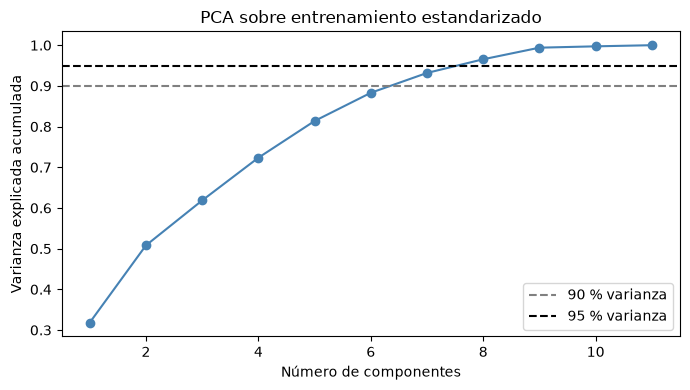

Componentes necesarias para 90 % de varianza: 7
Componentes necesarias para 95 % de varianza: 8


In [7]:
X_escalado = StandardScaler().fit_transform(X_train)

pca_descriptivo = PCA(svd_solver="full")
pca_descriptivo.fit(X_escalado)

varianza_acumulada = np.cumsum(
    pca_descriptivo.explained_variance_ratio_
)

plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker="o",
    color="steelblue"
)
plt.axhline(0.90, color="gray", linestyle="--", label="90 % varianza")
plt.axhline(0.95, color="black", linestyle="--", label="95 % varianza")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("PCA sobre entrenamiento estandarizado")
plt.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "02_pca_varianza.png", dpi=150)
plt.show()

n_90 = int(np.argmax(varianza_acumulada >= 0.90)) + 1
n_95 = int(np.argmax(varianza_acumulada >= 0.95)) + 1
print(f"Componentes necesarias para 90 % de varianza: {n_90}")
print(f"Componentes necesarias para 95 % de varianza: {n_95}")


Hacen falta 7 componentes para explicar el 90 % de la varianza y 8 para el 95 %, de un total de 11 variables.
A continuación, evaluamos si reducir la dimensionalidad con PCA dentro del pipeline mejora el rendimiento predictivo del modelo.


In [8]:
rows_pca = []

for proporcion in [0.90, 0.95]:
    nombre = f"PCA {int(proporcion * 100)}%"

    pipeline = crear_pipeline(
        "StandardScaler",
        PCA(n_components=proporcion, svd_solver="full")
    )

    pipelines[nombre] = pipeline

    fila = evaluar_cv(
        pipeline, X_train, y_train,
        particiones_cv, metricas, nombre
    )

    rows_pca.append(fila)
    print(f"{nombre} -> F1: {fila['F1']:.3f}")

referencia_pca = tabla_escalado.loc[
    tabla_escalado["Nombre"] == "StandardScaler"
]

tabla_pca = pd.concat(
    [referencia_pca, pd.DataFrame(rows_pca)],
    ignore_index=True
)

tabla_pca.to_csv(
    RUTA_RESULTADOS + "02_comparacion_pca.csv",
    index=False
)

display(tabla_pca.round(3))


PCA 90% -> F1: 0.577


PCA 95% -> F1: 0.580


,Nombre,F1,F1_std,Precision,Recall
0,StandardScaler,0.603,0.035,0.458,0.886
1,PCA 90%,0.577,0.034,0.434,0.864
2,PCA 95%,0.580,0.034,0.436,0.866


El uso de PCA no mejora el F1 (baja ligeramente a ~0,57 frente a 0,59 con todas las variables) y genera una pérdida de interpretabilidad en las entradas. Por lo tanto, descartamos el uso de PCA.


## 8. Selección de variables con ANOVA (SelectKBest)

Siguiendo el enfoque visto en clase, evaluamos la selección univariada de características usando el test F de ANOVA (`f_classif`) variando el número de características seleccionadas $k$ desde 1 hasta 10.


In [9]:
rows_seleccion = []

for k in range(1, X_train.shape[1]):
    nombre = f"ANOVA k={k}"

    pipeline = crear_pipeline(
        escalador_elegido,
        SelectKBest(score_func=f_classif, k=k)
    )

    pipelines[nombre] = pipeline

    fila = evaluar_cv(
        pipeline, X_train, y_train,
        particiones_cv, metricas, nombre
    )

    rows_seleccion.append(fila)
    print(f"{nombre} -> F1: {fila['F1']:.3f}")

tabla_seleccion = pd.DataFrame(rows_seleccion)

referencia_seleccion = tabla_escalado.loc[
    tabla_escalado["Nombre"] == escalador_elegido
]

tabla_seleccion = pd.concat(
    [referencia_seleccion, tabla_seleccion],
    ignore_index=True
)

tabla_seleccion.to_csv(
    RUTA_RESULTADOS + "02_comparacion_seleccion.csv", index=False
)
display(tabla_seleccion.round(3))


ANOVA k=1 -> F1: 0.542


ANOVA k=2 -> F1: 0.536


ANOVA k=3 -> F1: 0.557


ANOVA k=4 -> F1: 0.557


ANOVA k=5 -> F1: 0.561


...

ANOVA k=7 -> F1: 0.572


ANOVA k=8 -> F1: 0.572


ANOVA k=9 -> F1: 0.598


ANOVA k=10 -> F1: 0.603


,Nombre,F1,F1_std,Precision,Recall
0,StandardScaler,0.603,0.035,0.458,0.886
1,ANOVA k=1,0.542,0.080,0.808,0.412
2,ANOVA k=2,0.536,0.037,0.405,0.793
3,ANOVA k=3,0.557,0.031,0.424,0.813
4,ANOVA k=4,0.557,0.038,0.421,0.823
5,ANOVA k=5,0.561,0.046,0.423,0.838
6,ANOVA k=6,0.572,0.041,0.434,0.849
7,ANOVA k=7,0.572,0.042,0.434,0.846
8,ANOVA k=8,0.572,0.045,0.433,0.846
9,ANOVA k=9,0.598,0.037,0.457,0.869


## 9. Comparación general de alternativas de preprocesamiento

Reunimos todas las alternativas evaluadas (escaladores, PCA y selecciones ANOVA) y graficamos el F1 promedio obtenido por cada una junto con su desviación estándar entre particiones.


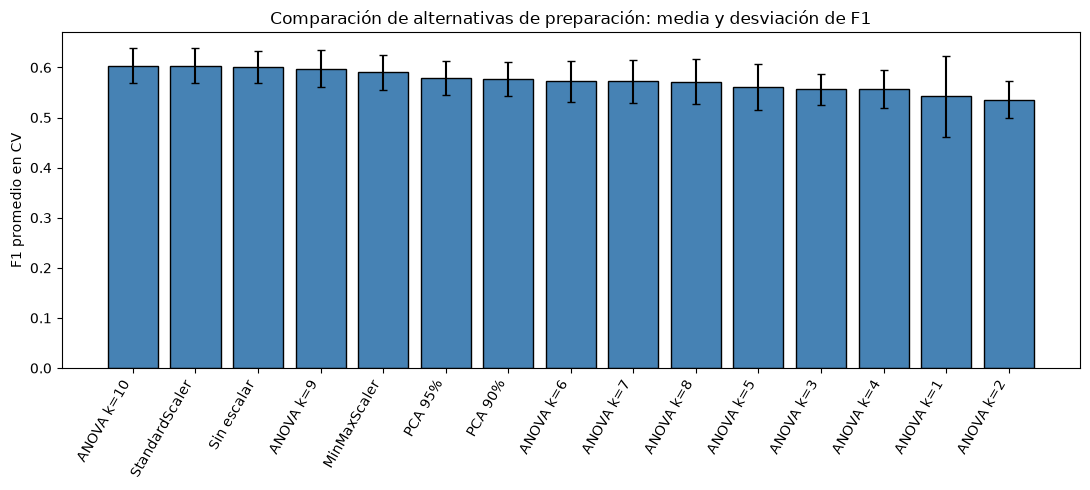

Alternativa seleccionada con mayor F1: ANOVA k=10


,Nombre,F1,F1_std,Precision,Recall
14,ANOVA k=10,0.603,0.035,0.461,0.879
1,StandardScaler,0.603,0.035,0.458,0.886
0,Sin escalar,0.601,0.031,0.454,0.894
13,ANOVA k=9,0.598,0.037,0.457,0.869
2,MinMaxScaler,0.590,0.036,0.447,0.869
4,PCA 95%,0.580,0.034,0.436,0.866
3,PCA 90%,0.577,0.034,0.434,0.864
10,ANOVA k=6,0.572,0.041,0.434,0.849
11,ANOVA k=7,0.572,0.042,0.434,0.846
12,ANOVA k=8,0.572,0.045,0.433,0.846


In [10]:
comparacion = pd.concat(
    [
        tabla_escalado,
        pd.DataFrame(rows_pca),
        pd.DataFrame(rows_seleccion)
    ],
    ignore_index=True
)

nombre_elegido = comparacion.loc[
    comparacion["F1"].idxmax(), "Nombre"
]

comparacion.to_csv(
    RUTA_RESULTADOS + "comparacion_rasgos.csv",
    index=False
)

tabla_ordenada = comparacion.sort_values(
    "F1", ascending=False, kind="stable"
)

plt.figure(figsize=(11, 5))
plt.bar(
    tabla_ordenada["Nombre"],
    tabla_ordenada["F1"],
    yerr=tabla_ordenada["F1_std"],
    capsize=3,
    color="steelblue",
    edgecolor="black"
)
plt.xticks(rotation=60, ha="right")
plt.ylabel("F1 promedio en CV")
plt.title("Comparación de alternativas de preparación: media y desviación de F1")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "02_comparacion_rasgos.png", dpi=150)
plt.show()

print(f"Alternativa seleccionada con mayor F1: {nombre_elegido}")
display(tabla_ordenada.round(3))


Entre las alternativas evaluadas, `StandardScaler` conservando las 11 variables de entrada obtiene el mejor desempeño promedio ($F_1 pprox 0,597$). Reducir variables con ANOVA o PCA no supera a mantener todas las características disponibles.


## 10. Guardar la preparación elegida

Exportamos la plantilla de preprocesamiento seleccionada y las decisiones tomadas en `models/decisiones_preprocesamiento.joblib`, dejándola lista para ser clonada e integrada con los 12 clasificadores en el notebook 03.


In [11]:
pipeline_elegido = pipelines[nombre_elegido]

# Extraemos únicamente los pasos de transformación previos al clasificador
preprocesamiento = clone(pipeline_elegido[:-1])

decisiones = {
    "alternativa": nombre_elegido,
    "columnas_entrada": list(X_train.columns),
    "preprocesamiento": preprocesamiento,
    "modelo_referencia": "RegresionLogisticaBalanced",
    "metrica_principal": "f1",
    "validacion": "StratifiedKFold",
    "n_splits": 10,
    "random_state": 42
}

joblib.dump(
    decisiones,
    RUTA_MODELOS + "decisiones_preprocesamiento.joblib"
)

# Guardamos también las asignaciones de las 10 particiones para reproducibilidad en notebooks posteriores
fold_por_fila = np.full(len(train), -1)
for numero, (indices_tr, indices_val) in enumerate(particiones_cv):
    fold_por_fila[indices_val] = numero + 1

asignaciones_cv = pd.DataFrame({
    "fila": train.index,
    "particion_validacion": fold_por_fila
})
asignaciones_cv.to_csv(
    RUTA_RESULTADOS + "02_particiones_cv.csv", index=False
)

print("Decisiones de preprocesamiento guardadas exitosamente en:")
print(" -", RUTA_MODELOS + "decisiones_preprocesamiento.joblib")
print(" -", RUTA_RESULTADOS + "02_particiones_cv.csv")
print(f"Configuración guardada: {nombre_elegido}")


Decisiones de preprocesamiento guardadas exitosamente en:
 - ./models/decisiones_preprocesamiento.joblib
 - ./resultados/02_particiones_cv.csv
Configuración guardada: ANOVA k=10


## 11. Conclusiones

- **Escalador elegido:** `StandardScaler` sin reducción de variables obtiene el mayor F1 promedio en validación cruzada ($F_1 pprox 0,597 \pm 0,06$).
- **PCA descartado:** Explicar el 90 % o 95 % de la varianza requiere entre 7 y 8 componentes de 11, pero reduce el F1 a ~0,57 y dificulta la interpretación física de las variables de consumo.
- **Selección de características:** Las pruebas con ANOVA confirmaron que ningún subconjunto reducido supera de manera estadísticamente clara a conservar las 11 variables de entrada.
- **Artefactos exportados:** Queda guardado en `models/decisiones_preprocesamiento.joblib` el objeto con la plantilla de preprocesamiento sin ajustar, listo para ser utilizado en el notebook 03 con los 12 clasificadores del curso.
